<style>
.jp-Notebook{background:#f5f7fa!important;padding:28px 20px!important}.jp-Cell{margin-bottom:20px!important}
.jp-MarkdownCell .jp-InputPrompt{display:none!important}.jp-MarkdownOutput{padding:0!important}
.jp-CodeCell .jp-InputArea{border:1px solid #dce3ec!important;border-radius:10px!important;background:#f8fafc!important;padding:14px 8px!important}
.jp-CodeCell .cm-content,.highlight pre{font-family:'SFMono-Regular',Consolas,monospace!important;font-size:14px!important;line-height:1.65!important}
.jp-OutputArea-output{padding:16px 12px!important}.jp-OutputArea-output pre{font-size:13px!important;line-height:1.65!important}
.jp-RenderedHTMLCommon table.dataframe{font-size:14px!important;border-collapse:collapse!important;line-height:1.6!important}
.jp-RenderedHTMLCommon table.dataframe th{background:#edf3f8!important;padding:11px 14px!important}
.jp-RenderedHTMLCommon table.dataframe td{padding:10px 14px!important;border-bottom:1px solid #e3eaf2!important}
.jp-RenderedHTMLCommon table.dataframe tbody tr:nth-child(even){background:#f8fafc!important}
.jp-OutputArea-output img{display:block;margin:18px auto!important;max-width:100%!important}
@media(max-width:700px){.pads-reading{padding:22px 18px!important}.jp-Notebook{padding:12px 4px!important}}
</style>
<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h1 style="font-size:35px;line-height:1.25;letter-spacing:-.02em;color:#152b46;margin:10px 0 22px;">Forecast the next value · student notebook</h1>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Two one-dimensional time series, two independent recurrent architectures. <strong style="color:#203b58;font-weight:650;">Monthly sunspots: 12 values → the 13th. Daily minimum temperature: 24 values → the 25th.</strong> Every model predicts one number, not a class label.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Data downloading, auditing, chronological splits, scaling, windows, loaders and plots are completed. The empty cells are your implementation spaces. Follow the architecture and API instructions immediately above each one; RNN and LSTM are separate exercises.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">A window length defines the forecasting question. These windows deliberately use 12 or 24 observations; the recurrent layers themselves can process other sequence lengths without changing the one-feature input interface.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Local Jupyter and Google Colab are both suitable. A CPU is sufficient. Select the existing Python (swipe-lecture) kernel locally; the required packages are PyTorch, NumPy, pandas and Matplotlib.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Download-both-small-datasets" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 01</span>Download both small datasets</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The first code cell stores two CSV files under <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">data/forecasting</code>. Downloads are atomic, checksummed and reused. Download problems are reported rather than silently substituting a different dataset.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The sunspot archive contains monthly observations from 1749–1983. It is a historical series; it is not silently replaced with today’s revised live series. The second CSV contains daily minimum temperature observations for 1981–1990. We audit its actual dates before constructing day-based windows.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;"><a href="https://github.com/jbrownlee/Datasets/blob/master/monthly-sunspots.csv" style="color:#147f86;text-underline-offset:3px;">Sunspot CSV archive</a> · <a href="https://github.com/jbrownlee/Datasets/blob/master/monthly-sunspots.names" style="color:#147f86;text-underline-offset:3px;">Sunspot source notes</a> · <a href="https://github.com/jbrownlee/Datasets/blob/master/daily-min-temperatures.csv" style="color:#147f86;text-underline-offset:3px;">Temperature CSV mirror</a> · <a href="https://github.com/jbrownlee/Datasets/blob/master/daily-min-temperatures.names" style="color:#147f86;text-underline-offset:3px;">Temperature source notes</a></p>
</div>

In [ ]:
from pathlib import Path
import urllib.request
import hashlib

DATA = Path("data/forecasting")
DATA.mkdir(parents=True, exist_ok=True)
EXPECTED_HASHES = {
    "monthly-sunspots.csv": "c4ec8cc57d9f6fb6ecdb3e1f37f25b6f4badd5124c55931052b0cd2fc3bc71f3",
    "daily-min-temperatures.csv": "8b9de63ed6789492bf497625e7f9beb96a63d367b4b0a21754006f749fa5e5da",
}
for filename, expected in EXPECTED_HASHES.items():
    path = DATA / filename
    if not path.exists():
        temporary = path.with_suffix(".download")
        with urllib.request.urlopen(
            "https://raw.githubusercontent.com/jbrownlee/Datasets/master/" + filename,
            timeout=30,
        ) as response:
            temporary.write_bytes(response.read())
        assert (
            hashlib.sha256(temporary.read_bytes()).hexdigest() == expected
        ), "Dataset checksum changed: inspect the source."
        temporary.replace(path)
    assert (
        hashlib.sha256(path.read_bytes()).hexdigest() == expected
    ), "Cached dataset checksum failed."
    print(filename, "| verified bytes:", path.stat().st_size)


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Reproducible-session" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 02</span>Reproducible session</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The seed is 42 and computation uses four CPU threads. No environment is created inside a cell: its interpreter is selected through the notebook kernel. If needed in Colab, install packages with <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">%pip install torch numpy pandas matplotlib</code> before running the imports.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The imports below are provided for both versions, including the APIs needed in the empty exercise cells.</p>
</div>

In [ ]:
import copy
import json
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display, HTML

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
DEVICE = torch.device("cpu")
RESULTS = Path("results_forecasting_student")
RESULTS.mkdir(exist_ok=True)
plt.rcParams.update(
    {
        "font.size": 13,
        "figure.dpi": 120,
        "axes.titlesize": 17,
        "axes.titleweight": "bold",
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
display(
    HTML(
        "<style>\n.jp-Notebook{background:#f5f7fa!important;padding:28px 20px!important}.jp-Cell{margin-bottom:20px!important}\n.jp-MarkdownCell .jp-InputPrompt{display:none!important}.jp-MarkdownOutput{padding:0!important}\n.jp-CodeCell .jp-InputArea{border:1px solid #dce3ec!important;border-radius:10px!important;background:#f8fafc!important;padding:14px 8px!important}\n.jp-CodeCell .cm-content,.highlight pre{font-family:'SFMono-Regular',Consolas,monospace!important;font-size:14px!important;line-height:1.65!important}\n.jp-OutputArea-output{padding:16px 12px!important}.jp-OutputArea-output pre{font-size:13px!important;line-height:1.65!important}\n.jp-RenderedHTMLCommon table.dataframe{font-size:14px!important;border-collapse:collapse!important;line-height:1.6!important}\n.jp-RenderedHTMLCommon table.dataframe th{background:#edf3f8!important;padding:11px 14px!important}\n.jp-RenderedHTMLCommon table.dataframe td{padding:10px 14px!important;border-bottom:1px solid #e3eaf2!important}\n.jp-RenderedHTMLCommon table.dataframe tbody tr:nth-child(even){background:#f8fafc!important}\n.jp-OutputArea-output img{display:block;margin:18px auto!important;max-width:100%!important}\n@media(max-width:700px){.pads-reading{padding:22px 18px!important}.jp-Notebook{padding:12px 4px!important}}\n</style>"
    )
)
print("PyTorch:", torch.__version__, "| device:", DEVICE)


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="What-makes-a-forecast-example?" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 03</span>What makes a forecast example?</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">For an observed scalar series $v_t$, an input consists of the previous $L$ values. Its target is the immediately following value:</p>
<p style="font-size:18px;line-height:1.8;padding:18px 20px;background:#f1f6fa;border:1px solid #e4ecf3;border-radius:8px;margin:20px 0;overflow-x:auto;text-align:center;">$$X_t=[v_{t-L},\ldots,v_{t-1}],\qquad y_t=v_t.$$</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">A batch has shape <strong style="color:#203b58;font-weight:650;">B × L × 1</strong>. The final 1 means one feature per observation, not one time step. Targets have shape <strong style="color:#203b58;font-weight:650;">B × 1</strong>. We use mean-squared error for training, and MAE and RMSE in original units for evaluation. An accuracy percentage is not a regression metric.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The target date assigns a window to training, validation or testing. The split is chronological, 70% / 15% / 15% of the raw observations, with integer rounding. Scaling statistics come exclusively from the raw training period. Context windows may cross an earlier partition boundary because those earlier observations are already available.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Testing is <strong style="color:#203b58;font-weight:650;">rolling one-step prediction</strong>: forecasting a test date can use actual observations from earlier test dates. It is different from predicting the whole test period recursively from the training cutoff. Test labels never select epochs or model settings.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Monthly-sunspot-number-%C2%B7-inspect-the-raw-observations" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 04</span>Monthly sunspot number · inspect the raw observations</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The model receives only the scalar <strong style="color:#203b58;font-weight:650;">Sunspots</strong> column. Dates organize ordering, continuity checks and plots; they are not extra input features. We use <strong style="color:#203b58;font-weight:650;">12 previous observations</strong> to predict the next one.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Twelve months of history predict the next monthly sunspot number. This short history does not span a full solar cycle; it illustrates short-horizon forecasting rather than physical solar-cycle modeling.</p>
</div>

In [ ]:
sun_df = pd.read_csv(DATA / "monthly-sunspots.csv")
sun_df["Month"] = pd.to_datetime(sun_df["Month"])
sun_df["Sunspots"] = pd.to_numeric(sun_df["Sunspots"])
assert sun_df["Month"].is_monotonic_increasing and sun_df["Month"].is_unique
assert np.isfinite(sun_df["Sunspots"]).all()
sun_dates = sun_df["Month"]
sun_values = sun_df["Sunspots"].to_numpy(dtype=np.float32)
sun_calendar = sun_dates.dt.to_period("M").astype("int64").to_numpy()
sun_gaps = np.flatnonzero(np.diff(sun_calendar) != 1) + 1
print(
    "Observations:",
    len(sun_df),
    "| range:",
    sun_dates.iloc[0],
    "to",
    sun_dates.iloc[-1],
)
print("Calendar gaps:", len(sun_gaps))
display(sun_df.head(8))
if len(sun_gaps):
    display(sun_df.iloc[sun_gaps])
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(sun_dates, sun_values, color="#19878c", lw=1.4)
ax.set_title("Monthly sunspot number")
ax.set_xlabel("Date")
ax.set_ylabel("Sunspot number")
plt.tight_layout()
plt.show()


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Chronological-partitions,-training-only-scaling-and-12-value-windows" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Chronological partitions, training-only scaling and 12-value windows</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The code below creates all completed inputs for the exercises. Each window is retained only when its <strong style="color:#203b58;font-weight:650;">input dates and target date are consecutive</strong>. A missing date is not filled with a future value or silently treated as an ordinary interval.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Training windows may be shuffled by the loader; the values within each window remain ordered. Validation and test loaders preserve target order. The raw training mean and standard deviation are saved for reversing the transformation.</p>
<p style="font-size:18px;line-height:1.8;padding:18px 20px;background:#f1f6fa;border:1px solid #e4ecf3;border-radius:8px;margin:20px 0;overflow-x:auto;text-align:center;">$$z_t=\frac{v_t-\mu_{train}}{\sigma_{train}},\qquad \hat v_t=\hat z_t\sigma_{train}+\mu_{train}.$$</p>
</div>

In [ ]:
sun_WINDOW = 12
sun_train_end = int(0.70 * len(sun_values))
sun_val_end = int(0.85 * len(sun_values))
sun_mean = float(sun_values[:sun_train_end].mean())
sun_std = max(float(sun_values[:sun_train_end].std()), 1e-6)
sun_scaled = (sun_values - sun_mean) / sun_std
sun_windows = []
sun_targets = []
sun_target_indices = []
sun_excluded = 0
for target in range(sun_WINDOW, len(sun_values)):
    if not np.all(np.diff(sun_calendar[target - sun_WINDOW : target + 1]) == 1):
        sun_excluded += 1
        continue
    sun_windows.append(sun_scaled[target - sun_WINDOW : target])
    sun_targets.append(sun_scaled[target])
    sun_target_indices.append(target)
sun_X_all = torch.tensor(np.asarray(sun_windows), dtype=torch.float32).unsqueeze(-1)
sun_y_all = torch.tensor(np.asarray(sun_targets), dtype=torch.float32).unsqueeze(-1)
sun_target_indices = np.array(sun_target_indices)
sun_train_mask = sun_target_indices < sun_train_end
sun_val_mask = (sun_target_indices >= sun_train_end) & (
    sun_target_indices < sun_val_end
)
sun_test_mask = sun_target_indices >= sun_val_end
sun_X_train = sun_X_all[sun_train_mask]
sun_y_train = sun_y_all[sun_train_mask]
sun_X_val = sun_X_all[sun_val_mask]
sun_y_val = sun_y_all[sun_val_mask]
sun_X_test = sun_X_all[sun_test_mask]
sun_y_test = sun_y_all[sun_test_mask]
sun_train_loader = DataLoader(
    TensorDataset(sun_X_train, sun_y_train),
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
sun_val_loader = DataLoader(
    TensorDataset(sun_X_val, sun_y_val), batch_size=128, shuffle=False
)
sun_test_loader = DataLoader(
    TensorDataset(sun_X_test, sun_y_test), batch_size=128, shuffle=False
)
sun_manifest = pd.DataFrame(
    {
        "target_index": sun_target_indices,
        "target_date": sun_dates.iloc[sun_target_indices].to_numpy(),
        "input_start_index": sun_target_indices - sun_WINDOW,
        "input_end_index": sun_target_indices - 1,
        "split": np.where(
            sun_train_mask, "train", np.where(sun_val_mask, "validation", "test")
        ),
    }
)
assert sun_manifest.target_index.is_unique
assert len(sun_X_all) == len(sun_y_train) + len(sun_y_val) + len(sun_y_test)
assert sun_X_all.shape[1:] == (12, 1)
sun_manifest.to_csv(RESULTS / "sun_split_manifest.csv", index=False)
(RESULTS / "sun_scaler.json").write_text(
    json.dumps(
        {
            "mean": sun_mean,
            "std": sun_std,
            "window": 12,
            "train_end": sun_train_end,
            "val_end": sun_val_end,
        }
    )
)
print("Excluded windows crossing calendar gaps:", sun_excluded)
print(
    "Training / validation / testing targets:",
    len(sun_y_train),
    len(sun_y_val),
    len(sun_y_test),
)
print(
    "X shapes:",
    tuple(sun_X_train.shape),
    tuple(sun_X_val.shape),
    tuple(sun_X_test.shape),
)
print(
    "Target shapes:",
    tuple(sun_y_train.shape),
    tuple(sun_y_val.shape),
    tuple(sun_y_test.shape),
)
display(
    sun_manifest.groupby("split").agg(
        targets=("target_index", "size"),
        first_date=("target_date", "min"),
        last_date=("target_date", "max"),
    )
)


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Visualize-the-partitions-and-one-input%E2%80%93target-pair" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Visualize the partitions and one input–target pair</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The colored regions show target partitions. For the first retained example, the connected <strong style="color:#203b58;font-weight:650;">12 input points</strong> precede the highlighted <strong style="color:#203b58;font-weight:650;">next-value target</strong>. The table displays the values in original units, so the learning problem is visible before any network is defined.</p>
</div>

In [ ]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(sun_dates, sun_values, color="#29465f", lw=1.3)
for start, end, label, color in [
    (0, sun_train_end, "Training", "#19878c"),
    (sun_train_end, sun_val_end, "Validation", "#d59a39"),
    (sun_val_end, len(sun_values), "Testing", "#9d77b5"),
]:
    ax.axvspan(
        sun_dates.iloc[start],
        sun_dates.iloc[end - 1],
        color=color,
        alpha=0.15,
        label=label,
    )
ax.set_title("Chronological target partitions")
ax.set_ylabel("Sunspot number")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
sun_example_target = int(sun_target_indices[0])
sun_example_start = sun_example_target - sun_WINDOW
sun_example = pd.DataFrame(
    {
        "date": sun_dates.iloc[sun_example_start : sun_example_target + 1].to_numpy(),
        "value": sun_values[sun_example_start : sun_example_target + 1],
        "role": ["input"] * sun_WINDOW + ["next target"],
    }
)
display(sun_example)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(
    sun_example.date.iloc[:-1],
    sun_example.value.iloc[:-1],
    marker="o",
    label="12 past values",
    color="#19878c",
)
ax.scatter(
    sun_example.date.iloc[-1],
    sun_example.value.iloc[-1],
    s=100,
    color="#d59a39",
    label="Next-value target",
    zorder=3,
)
ax.set_title("One sequence → one numeric target")
ax.set_ylabel("Sunspot number")
ax.legend()
plt.tight_layout()
plt.show()


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Available-variables-for-this-experiment" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Available variables for this experiment</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_X_train</code>, <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_y_train</code>, <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_X_val</code>, <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_y_val</code>, <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_X_test</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_y_test</code>. The corresponding loaders are <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_train_loader</code>, <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_val_loader</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_test_loader</code>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_mean</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_std</code> convert a scaled prediction back to <strong style="color:#203b58;font-weight:650;">sunspot number</strong>. Target indices and masks align predictions with dates. There is no need to rebuild or randomly resplit the prepared windows.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Monthly-sunspot-number-%C2%B7-RNN-architecture" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 05</span>Monthly sunspot number · RNN architecture</h2><p style="font-size:18px;line-height:1.8;padding:18px 20px;background:#f1f6fa;border:1px solid #e4ecf3;border-radius:8px;margin:20px 0;overflow-x:auto;text-align:center;">$$h_t=\tanh(W_{ih}x_t+b_{ih}+W_{hh}h_{t-1}+b_{hh}),\qquad \hat z=w^Th_L+b.$$</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The simple RNN repeatedly combines the current scalar input and previous 32-component hidden state. Gradients through repeated updates can shrink or grow.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use exactly <strong style="color:#203b58;font-weight:650;">one recurrent layer, one input feature and 32 hidden components</strong>. The fully connected output head is <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.Linear(32, 1)</code>. It is a regression head with <strong style="color:#203b58;font-weight:650;">one output neuron</strong> and no softmax or sigmoid. Select only the final hidden state; no hidden-state averaging or concatenation is needed.</p>
<table>
<thead>
<tr>
<th>Stage</th>
<th>Shape</th>
<th>Meaning</th>
</tr>
</thead>
<tbody>
<tr>
<td>Input</td>
<td>B × 12 × 1</td>
<td>Ordered scalar observations</td>
</tr>
<tr>
<td>All recurrent outputs</td>
<td>B × 12 × 32</td>
<td>One hidden vector per step</td>
</tr>
<tr>
<td>Final hidden returned by layer</td>
<td>1 × B × 32</td>
<td>One layer, B windows</td>
</tr>
<tr>
<td>Final features</td>
<td>B × 32</td>
<td>Select the last layer</td>
</tr>
<tr>
<td>Linear forecast</td>
<td>B × 1</td>
<td>Next scaled value</td>
</tr>
</tbody>
</table>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Initial states are zero for every window; they are not carried between unrelated minibatches.</p>
</div>

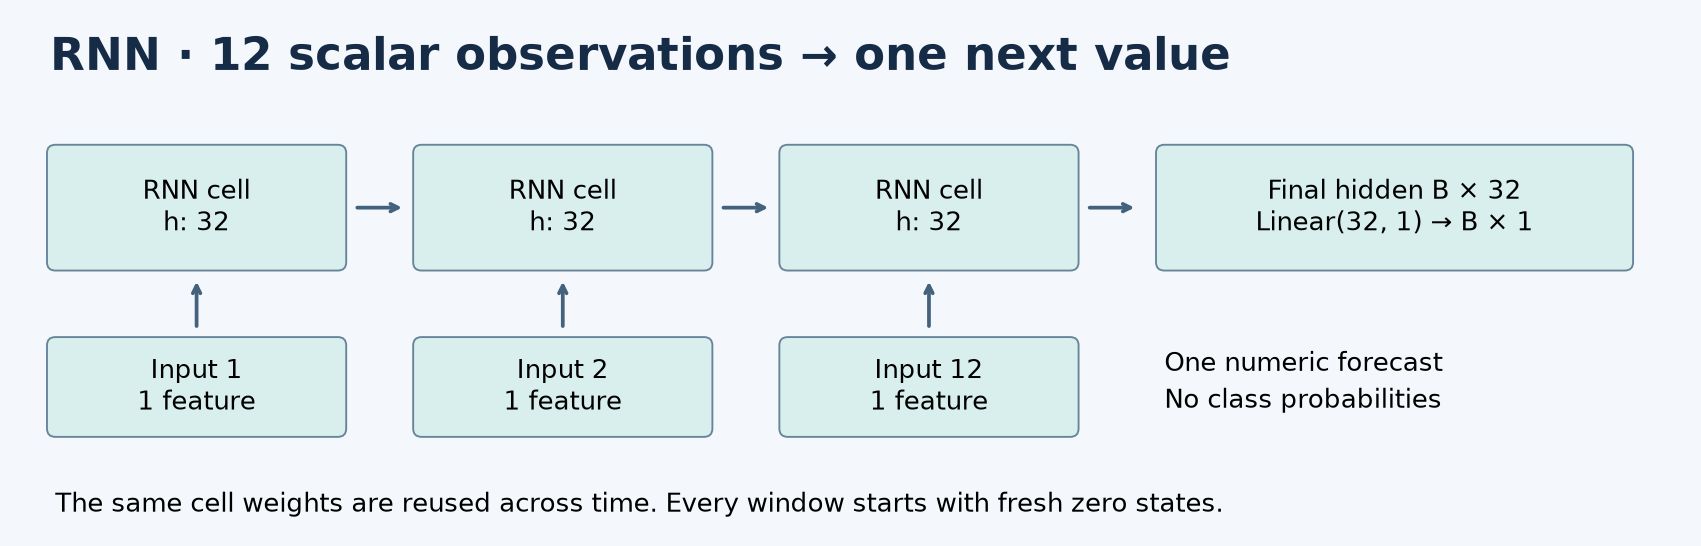

<div style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;font-size:13px;color:#64748b;text-align:center;margin:8px 0 22px">RNN architecture: 12 inputs, 32 hidden components, one regression output</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Build-and-inspect-SunspotRNNForecaster" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Build and inspect <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">SunspotRNNForecaster</code></h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Create a class inheriting from <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.Module</code>, call <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">super().__init__()</code>, and define a <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">recurrent</code> layer using <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.RNN(input_size=1, hidden_size=32, num_layers=1, batch_first=True)</code></strong>. Define a separate <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">head</code> using <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.Linear(32, 1)</code></strong>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">In <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">forward(x)</code>, call the recurrent layer. RNN returns the sequence outputs and final hidden tensor. Select the final layer from the hidden tensor, then pass that B × 32 vector to the linear head.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Set the seed with <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">torch.manual_seed(SEED)</code>, instantiate <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_rnn_model</code>, and move it to <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">DEVICE</code>. Print the module, count trainable parameters using <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sum(parameter.numel() for parameter in model.parameters())</code>, and demonstrate <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_X_train[:4] → (4, 1)</code>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Expected parameter count: <strong style="color:#203b58;font-weight:650;">1153</strong>. This includes recurrent input weights, recurrent hidden weights, both bias vectors and the linear head. Check shapes before beginning training.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;"><a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html" style="color:#147f86;text-underline-offset:3px;">PyTorch RNN API</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html" style="color:#147f86;text-underline-offset:3px;">Linear layer</a></p>
</div>

In [ ]:
class SunspotRNNForecaster(nn.Module):
    """
    One-layer RNN that forecasts the next scaled sunspot
    """


    def __init__(self):
        """
        Build a 32-unit RNN and a one-neuron regression head.
        """
        super().__init__()
        self.recurrent = nn.RNN(
            input_size=1,
            hidden_size=32,
            num_layers=1,
            batch_first=True,
        )
        self.head = nn.Linear(32, 1)
    

    def forward(self, x):
        """
        Map a batch of windows to one scaled forecast each.
        """
        _, hidden = self.recurrent(x)

        return self.head(hidden[-1])


torch.manual_seed(SEED)
sun_rnn_model = SunspotRNNForecaster().to(DEVICE)
print(sun_rnn_model)
print(
    'Trainale params:',
    sum(p.numel() for p in sun_rnn_model.parameters()),
)
sample = sun_rnn_model(sun_X_train[:4].to(DEVICE))
print(tuple(sun_X_train[:4].shape), '->', tuple(sample.shape))


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Train-RNN-independently-and-select-a-validation-checkpoint" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Train RNN independently and select a validation checkpoint</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.MSELoss()</code></strong>, <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">torch.optim.Adam(sun_rnn_model.parameters(), lr=0.001)</code></strong>, at most <strong style="color:#203b58;font-weight:650;">100 epochs</strong>, and early-stopping patience <strong style="color:#203b58;font-weight:650;">15</strong>. Keep this model’s optimizer, history and best weights separate from the other model.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">For every epoch, switch to <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">model.train()</code>. Iterate over <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_train_loader</code>, move inputs and targets to <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">DEVICE</code>, call <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">optimizer.zero_grad()</code>, calculate predictions and MSE, call <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">loss.backward()</code>, clip using <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.utils.clip_grad_norm_(model.parameters(), 1.0)</code></strong>, then call <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">optimizer.step()</code>. Average training losses weighted by batch size.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Next, use <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">model.eval()</code> and <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">with torch.no_grad():</code></strong> for <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_val_loader</code>. Compute validation MSE without updating weights. Append training and validation losses to a history. If validation MSE improves by more than <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">1e-5</code>, save <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">copy.deepcopy(model.state_dict())</code></strong>, remember the epoch and reset the stale counter. Otherwise increment it. Stop when the counter reaches patience.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Restore the best weights with <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">model.load_state_dict(best_weights)</code></strong>. The criterion is the lowest validation MSE, not the lowest training MSE or the latest epoch. Test values must not select the checkpoint. Store this model’s results in <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_rnn_history</code>, <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_rnn_best_epoch</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_rnn_seconds</code>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">MSE compares tensors of shape <strong style="color:#203b58;font-weight:650;">B × 1</strong>. Accidentally comparing B × 1 with B can broadcast to B × B and train the wrong problem; keep the target dimension.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Evaluate-RNN,-reverse-scaling-and-draw-the-results" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Evaluate RNN, reverse scaling and draw the results</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">model.eval()</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">torch.no_grad()</code> to predict <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_X_test</code> in its existing order. Keep predictions in <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_rnn_prediction_scaled</code>, then convert to original units using <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_std</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_mean</code>; call the result <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_rnn_prediction</code>. Convert <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_y_test</code> the same way to <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_actual</code>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Calculate <strong style="color:#203b58;font-weight:650;">MAE</strong> as <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">np.mean(np.abs(prediction - actual))</code> and <strong style="color:#203b58;font-weight:650;">RMSE</strong> as <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">np.sqrt(np.mean((prediction - actual) ** 2))</code>. Save these in a dictionary <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_rnn_metrics</code>, together with model name, selected epoch and measured training time. Lower errors are better. We omit MAPE because the temperature data include zero values.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Draw two figures: the training/validation MSE histories, then actual versus predicted values on test target dates. Align dates with <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_dates.iloc[sun_target_indices[sun_test_mask]]</code>. Add axis labels, units and a legend. Display a small date/actual/prediction/error table.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Expected result: <strong style="color:#203b58;font-weight:650;">one prediction for every test target</strong>, never one class per sequence. Restore the selected validation checkpoint before evaluating.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Monthly-sunspot-number-%C2%B7-LSTM-architecture" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 06</span>Monthly sunspot number · LSTM architecture</h2><p style="font-size:18px;line-height:1.8;padding:18px 20px;background:#f1f6fa;border:1px solid #e4ecf3;border-radius:8px;margin:20px 0;overflow-x:auto;text-align:center;">$$i_t=\sigma(W_i x_t+U_i h_{t-1}+b_i),\quad f_t=\sigma(W_f x_t+U_f h_{t-1}+b_f)$$
$$g_t=\tanh(W_g x_t+U_g h_{t-1}+b_g),\quad o_t=\sigma(W_o x_t+U_o h_{t-1}+b_o)$$
$$c_t=f_t\odot c_{t-1}+i_t\odot g_t,\quad h_t=o_t\odot\tanh(c_t),\quad \hat z=w^Th_L+b.$$</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The LSTM carries hidden h and cell memory c, each with 32 components. Forget, input and output gates control retained, written and exposed information. Sigmoid gates range from zero to one; the element-wise product is written with the symbol ⊙.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use exactly <strong style="color:#203b58;font-weight:650;">one recurrent layer, one input feature and 32 hidden components</strong>. The fully connected output head is <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.Linear(32, 1)</code>. It is a regression head with <strong style="color:#203b58;font-weight:650;">one output neuron</strong> and no softmax or sigmoid. Select only the final hidden state; no hidden-state averaging or concatenation is needed.</p>
<table>
<thead>
<tr>
<th>Stage</th>
<th>Shape</th>
<th>Meaning</th>
</tr>
</thead>
<tbody>
<tr>
<td>Input</td>
<td>B × 12 × 1</td>
<td>Ordered scalar observations</td>
</tr>
<tr>
<td>All recurrent outputs</td>
<td>B × 12 × 32</td>
<td>One hidden vector per step</td>
</tr>
<tr>
<td>Final hidden returned by layer</td>
<td>1 × B × 32</td>
<td>One layer, B windows</td>
</tr>
<tr>
<td>Final features</td>
<td>B × 32</td>
<td>Select the last layer</td>
</tr>
<tr>
<td>Linear forecast</td>
<td>B × 1</td>
<td>Next scaled value</td>
</tr>
</tbody>
</table>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Initial states are zero for every window; they are not carried between unrelated minibatches.</p>
</div>

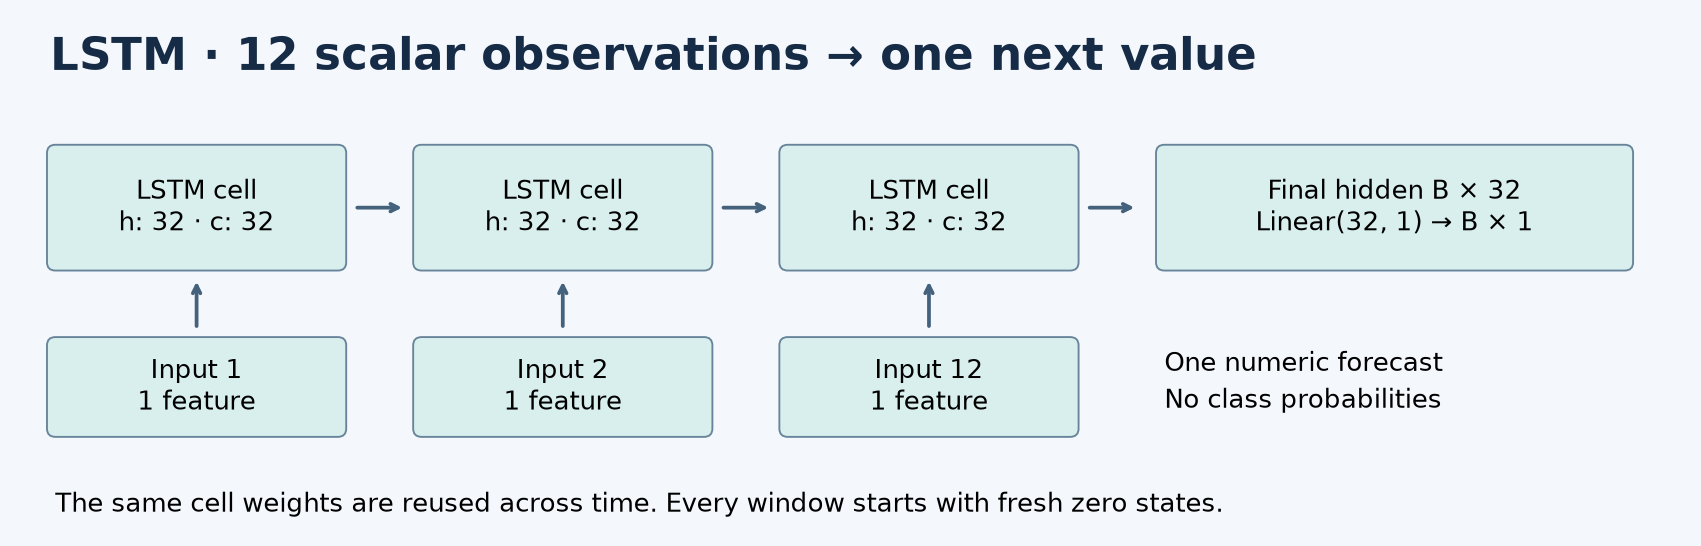

<div style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;font-size:13px;color:#64748b;text-align:center;margin:8px 0 22px">LSTM architecture: 12 inputs, 32 hidden components, one regression output</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Build-and-inspect-SunspotLSTMForecaster" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Build and inspect <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">SunspotLSTMForecaster</code></h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Create a class inheriting from <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.Module</code>, call <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">super().__init__()</code>, and define a <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">recurrent</code> layer using <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.LSTM(input_size=1, hidden_size=32, num_layers=1, batch_first=True)</code></strong>. Define a separate <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">head</code> using <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.Linear(32, 1)</code></strong>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">In <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">forward(x)</code>, call the recurrent layer. LSTM returns sequence outputs and a tuple of final hidden and final cell tensors; unpack that tuple and use hidden, not cell. Select the final layer from the hidden tensor, then pass that B × 32 vector to the linear head.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Set the seed with <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">torch.manual_seed(SEED)</code>, instantiate <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_lstm_model</code>, and move it to <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">DEVICE</code>. Print the module, count trainable parameters using <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sum(parameter.numel() for parameter in model.parameters())</code>, and demonstrate <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_X_train[:4] → (4, 1)</code>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Expected parameter count: <strong style="color:#203b58;font-weight:650;">4513</strong>. This includes recurrent input weights, recurrent hidden weights, both bias vectors and the linear head. Check shapes before beginning training.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;"><a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html" style="color:#147f86;text-underline-offset:3px;">PyTorch LSTM API</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html" style="color:#147f86;text-underline-offset:3px;">Linear layer</a></p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Train-LSTM-independently-and-select-a-validation-checkpoint" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Train LSTM independently and select a validation checkpoint</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.MSELoss()</code></strong>, <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">torch.optim.Adam(sun_lstm_model.parameters(), lr=0.001)</code></strong>, at most <strong style="color:#203b58;font-weight:650;">100 epochs</strong>, and early-stopping patience <strong style="color:#203b58;font-weight:650;">15</strong>. Keep this model’s optimizer, history and best weights separate from the other model.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">For every epoch, switch to <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">model.train()</code>. Iterate over <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_train_loader</code>, move inputs and targets to <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">DEVICE</code>, call <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">optimizer.zero_grad()</code>, calculate predictions and MSE, call <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">loss.backward()</code>, clip using <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.utils.clip_grad_norm_(model.parameters(), 1.0)</code></strong>, then call <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">optimizer.step()</code>. Average training losses weighted by batch size.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Next, use <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">model.eval()</code> and <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">with torch.no_grad():</code></strong> for <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_val_loader</code>. Compute validation MSE without updating weights. Append training and validation losses to a history. If validation MSE improves by more than <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">1e-5</code>, save <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">copy.deepcopy(model.state_dict())</code></strong>, remember the epoch and reset the stale counter. Otherwise increment it. Stop when the counter reaches patience.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Restore the best weights with <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">model.load_state_dict(best_weights)</code></strong>. The criterion is the lowest validation MSE, not the lowest training MSE or the latest epoch. Test values must not select the checkpoint. Store this model’s results in <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_lstm_history</code>, <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_lstm_best_epoch</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_lstm_seconds</code>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">MSE compares tensors of shape <strong style="color:#203b58;font-weight:650;">B × 1</strong>. Accidentally comparing B × 1 with B can broadcast to B × B and train the wrong problem; keep the target dimension.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Evaluate-LSTM,-reverse-scaling-and-draw-the-results" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Evaluate LSTM, reverse scaling and draw the results</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">model.eval()</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">torch.no_grad()</code> to predict <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_X_test</code> in its existing order. Keep predictions in <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_lstm_prediction_scaled</code>, then convert to original units using <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_std</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_mean</code>; call the result <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_lstm_prediction</code>. Convert <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_y_test</code> the same way to <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_actual</code>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Calculate <strong style="color:#203b58;font-weight:650;">MAE</strong> as <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">np.mean(np.abs(prediction - actual))</code> and <strong style="color:#203b58;font-weight:650;">RMSE</strong> as <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">np.sqrt(np.mean((prediction - actual) ** 2))</code>. Save these in a dictionary <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_lstm_metrics</code>, together with model name, selected epoch and measured training time. Lower errors are better. We omit MAPE because the temperature data include zero values.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Draw two figures: the training/validation MSE histories, then actual versus predicted values on test target dates. Align dates with <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_dates.iloc[sun_target_indices[sun_test_mask]]</code>. Add axis labels, units and a legend. Display a small date/actual/prediction/error table.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Expected result: <strong style="color:#203b58;font-weight:650;">one prediction for every test target</strong>, never one class per sequence. Restore the selected validation checkpoint before evaluating.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Monthly-sunspot-number-%C2%B7-compare-RNN,-LSTM-and-simple-baselines" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 07</span>Monthly sunspot number · compare RNN, LSTM and simple baselines</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Construct a table from <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_rnn_metrics</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_lstm_metrics</code>. Compare their test errors against <strong style="color:#203b58;font-weight:650;">persistence</strong>: predict the most recent observed value, obtained from <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_X_test[:, -1, 0]</code> and reversed through the scaler.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">A longer history or a gated network does not guarantee a smaller test error. Compare errors, not network complexity. Sunspots are not assumed to have a yearly seasonal cycle.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use the same test target dates for every predictor. Plot MAE and RMSE with separate axes, labels and a legend outside the bars. Record the measured ranking without changing settings based on the test results.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Monthly-sunspot-number-%C2%B7-optional-recursive-forecast" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 08</span>Monthly sunspot number · optional recursive forecast</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Start from the last <strong style="color:#203b58;font-weight:650;">12 observed scaled values</strong> of the complete series. For each of <strong style="color:#203b58;font-weight:650;">12 future steps</strong>, create a float32 tensor with shape <strong style="color:#203b58;font-weight:650;">1 × 12 × 1</strong>, predict with the selected LSTM under <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">torch.no_grad()</code>, append that scalar to the rolling history, and repeat. Later inputs contain predictions, so errors can accumulate.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Reverse scaling for the forecast and use future dates with frequency <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">MS</code>. Plot recent observed values separately from forecasts and mark the dataset’s final date. These predictions are beyond the historical file’s endpoint; there are no observed future targets in this archive. Do not report test MAE for this unobserved horizon.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sun_lstm_model</code> as selected by validation. It is not refitted on validation or test targets. This optional extension demonstrates feedback, not a guaranteed future trajectory.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Daily-minimum-temperature-%C2%B7-inspect-the-raw-observations" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 09</span>Daily minimum temperature · inspect the raw observations</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The model receives only the scalar <strong style="color:#203b58;font-weight:650;">Temp</strong> column. Dates organize ordering, continuity checks and plots; they are not extra input features. We use <strong style="color:#203b58;font-weight:650;">24 previous observations</strong> to predict the next one.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Daily temperature has short-range dependence and seasonal variation. A 24-day window is a practical history choice, not a complete annual seasonal cycle. The CSV omits 31 December in 1984 and 1988; we keep the raw data and exclude windows crossing either missing date.</p>
</div>

In [ ]:
temp_df = pd.read_csv(DATA / "daily-min-temperatures.csv")
temp_df["Date"] = pd.to_datetime(temp_df["Date"])
temp_df["Temp"] = pd.to_numeric(temp_df["Temp"])
assert temp_df["Date"].is_monotonic_increasing and temp_df["Date"].is_unique
assert np.isfinite(temp_df["Temp"]).all()
temp_dates = temp_df["Date"]
temp_values = temp_df["Temp"].to_numpy(dtype=np.float32)
temp_calendar = temp_dates.dt.to_period("D").astype("int64").to_numpy()
temp_gaps = np.flatnonzero(np.diff(temp_calendar) != 1) + 1
print(
    "Observations:",
    len(temp_df),
    "| range:",
    temp_dates.iloc[0],
    "to",
    temp_dates.iloc[-1],
)
print("Calendar gaps:", len(temp_gaps))
display(temp_df.head(8))
if len(temp_gaps):
    display(temp_df.iloc[temp_gaps])
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(temp_dates, temp_values, color="#19878c", lw=1.4)
ax.set_title("Daily minimum temperature")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
plt.tight_layout()
plt.show()


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Chronological-partitions,-training-only-scaling-and-24-value-windows" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Chronological partitions, training-only scaling and 24-value windows</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The code below creates all completed inputs for the exercises. Each window is retained only when its <strong style="color:#203b58;font-weight:650;">input dates and target date are consecutive</strong>. A missing date is not filled with a future value or silently treated as an ordinary interval.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Training windows may be shuffled by the loader; the values within each window remain ordered. Validation and test loaders preserve target order. The raw training mean and standard deviation are saved for reversing the transformation.</p>
<p style="font-size:18px;line-height:1.8;padding:18px 20px;background:#f1f6fa;border:1px solid #e4ecf3;border-radius:8px;margin:20px 0;overflow-x:auto;text-align:center;">$$z_t=\frac{v_t-\mu_{train}}{\sigma_{train}},\qquad \hat v_t=\hat z_t\sigma_{train}+\mu_{train}.$$</p>
</div>

In [ ]:
temp_WINDOW = 24
temp_train_end = int(0.70 * len(temp_values))
temp_val_end = int(0.85 * len(temp_values))
temp_mean = float(temp_values[:temp_train_end].mean())
temp_std = max(float(temp_values[:temp_train_end].std()), 1e-6)
temp_scaled = (temp_values - temp_mean) / temp_std
temp_windows = []
temp_targets = []
temp_target_indices = []
temp_excluded = 0
for target in range(temp_WINDOW, len(temp_values)):
    if not np.all(np.diff(temp_calendar[target - temp_WINDOW : target + 1]) == 1):
        temp_excluded += 1
        continue
    temp_windows.append(temp_scaled[target - temp_WINDOW : target])
    temp_targets.append(temp_scaled[target])
    temp_target_indices.append(target)
temp_X_all = torch.tensor(np.asarray(temp_windows), dtype=torch.float32).unsqueeze(-1)
temp_y_all = torch.tensor(np.asarray(temp_targets), dtype=torch.float32).unsqueeze(-1)
temp_target_indices = np.array(temp_target_indices)
temp_train_mask = temp_target_indices < temp_train_end
temp_val_mask = (temp_target_indices >= temp_train_end) & (
    temp_target_indices < temp_val_end
)
temp_test_mask = temp_target_indices >= temp_val_end
temp_X_train = temp_X_all[temp_train_mask]
temp_y_train = temp_y_all[temp_train_mask]
temp_X_val = temp_X_all[temp_val_mask]
temp_y_val = temp_y_all[temp_val_mask]
temp_X_test = temp_X_all[temp_test_mask]
temp_y_test = temp_y_all[temp_test_mask]
temp_train_loader = DataLoader(
    TensorDataset(temp_X_train, temp_y_train),
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
temp_val_loader = DataLoader(
    TensorDataset(temp_X_val, temp_y_val), batch_size=128, shuffle=False
)
temp_test_loader = DataLoader(
    TensorDataset(temp_X_test, temp_y_test), batch_size=128, shuffle=False
)
temp_manifest = pd.DataFrame(
    {
        "target_index": temp_target_indices,
        "target_date": temp_dates.iloc[temp_target_indices].to_numpy(),
        "input_start_index": temp_target_indices - temp_WINDOW,
        "input_end_index": temp_target_indices - 1,
        "split": np.where(
            temp_train_mask, "train", np.where(temp_val_mask, "validation", "test")
        ),
    }
)
assert temp_manifest.target_index.is_unique
assert len(temp_X_all) == len(temp_y_train) + len(temp_y_val) + len(temp_y_test)
assert temp_X_all.shape[1:] == (24, 1)
temp_manifest.to_csv(RESULTS / "temp_split_manifest.csv", index=False)
(RESULTS / "temp_scaler.json").write_text(
    json.dumps(
        {
            "mean": temp_mean,
            "std": temp_std,
            "window": 24,
            "train_end": temp_train_end,
            "val_end": temp_val_end,
        }
    )
)
print("Excluded windows crossing calendar gaps:", temp_excluded)
print(
    "Training / validation / testing targets:",
    len(temp_y_train),
    len(temp_y_val),
    len(temp_y_test),
)
print(
    "X shapes:",
    tuple(temp_X_train.shape),
    tuple(temp_X_val.shape),
    tuple(temp_X_test.shape),
)
print(
    "Target shapes:",
    tuple(temp_y_train.shape),
    tuple(temp_y_val.shape),
    tuple(temp_y_test.shape),
)
display(
    temp_manifest.groupby("split").agg(
        targets=("target_index", "size"),
        first_date=("target_date", "min"),
        last_date=("target_date", "max"),
    )
)


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Visualize-the-partitions-and-one-input%E2%80%93target-pair" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Visualize the partitions and one input–target pair</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The colored regions show target partitions. For the first retained example, the connected <strong style="color:#203b58;font-weight:650;">24 input points</strong> precede the highlighted <strong style="color:#203b58;font-weight:650;">next-value target</strong>. The table displays the values in original units, so the learning problem is visible before any network is defined.</p>
</div>

In [ ]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(temp_dates, temp_values, color="#29465f", lw=1.3)
for start, end, label, color in [
    (0, temp_train_end, "Training", "#19878c"),
    (temp_train_end, temp_val_end, "Validation", "#d59a39"),
    (temp_val_end, len(temp_values), "Testing", "#9d77b5"),
]:
    ax.axvspan(
        temp_dates.iloc[start],
        temp_dates.iloc[end - 1],
        color=color,
        alpha=0.15,
        label=label,
    )
ax.set_title("Chronological target partitions")
ax.set_ylabel("Temperature (°C)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
temp_example_target = int(temp_target_indices[0])
temp_example_start = temp_example_target - temp_WINDOW
temp_example = pd.DataFrame(
    {
        "date": temp_dates.iloc[
            temp_example_start : temp_example_target + 1
        ].to_numpy(),
        "value": temp_values[temp_example_start : temp_example_target + 1],
        "role": ["input"] * temp_WINDOW + ["next target"],
    }
)
display(temp_example)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(
    temp_example.date.iloc[:-1],
    temp_example.value.iloc[:-1],
    marker="o",
    label="24 past values",
    color="#19878c",
)
ax.scatter(
    temp_example.date.iloc[-1],
    temp_example.value.iloc[-1],
    s=100,
    color="#d59a39",
    label="Next-value target",
    zorder=3,
)
ax.set_title("One sequence → one numeric target")
ax.set_ylabel("Temperature (°C)")
ax.legend()
plt.tight_layout()
plt.show()


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Available-variables-for-this-experiment" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Available variables for this experiment</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_X_train</code>, <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_y_train</code>, <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_X_val</code>, <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_y_val</code>, <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_X_test</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_y_test</code>. The corresponding loaders are <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_train_loader</code>, <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_val_loader</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_test_loader</code>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_mean</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_std</code> convert a scaled prediction back to <strong style="color:#203b58;font-weight:650;">temperature (°c)</strong>. Target indices and masks align predictions with dates. There is no need to rebuild or randomly resplit the prepared windows.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Daily-minimum-temperature-%C2%B7-RNN-architecture" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 10</span>Daily minimum temperature · RNN architecture</h2><p style="font-size:18px;line-height:1.8;padding:18px 20px;background:#f1f6fa;border:1px solid #e4ecf3;border-radius:8px;margin:20px 0;overflow-x:auto;text-align:center;">$$h_t=\tanh(W_{ih}x_t+b_{ih}+W_{hh}h_{t-1}+b_{hh}),\qquad \hat z=w^Th_L+b.$$</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The simple RNN repeatedly combines the current scalar input and previous 32-component hidden state. Gradients through repeated updates can shrink or grow.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use exactly <strong style="color:#203b58;font-weight:650;">one recurrent layer, one input feature and 32 hidden components</strong>. The fully connected output head is <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.Linear(32, 1)</code>. It is a regression head with <strong style="color:#203b58;font-weight:650;">one output neuron</strong> and no softmax or sigmoid. Select only the final hidden state; no hidden-state averaging or concatenation is needed.</p>
<table>
<thead>
<tr>
<th>Stage</th>
<th>Shape</th>
<th>Meaning</th>
</tr>
</thead>
<tbody>
<tr>
<td>Input</td>
<td>B × 24 × 1</td>
<td>Ordered scalar observations</td>
</tr>
<tr>
<td>All recurrent outputs</td>
<td>B × 24 × 32</td>
<td>One hidden vector per step</td>
</tr>
<tr>
<td>Final hidden returned by layer</td>
<td>1 × B × 32</td>
<td>One layer, B windows</td>
</tr>
<tr>
<td>Final features</td>
<td>B × 32</td>
<td>Select the last layer</td>
</tr>
<tr>
<td>Linear forecast</td>
<td>B × 1</td>
<td>Next scaled value</td>
</tr>
</tbody>
</table>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Initial states are zero for every window; they are not carried between unrelated minibatches.</p>
</div>

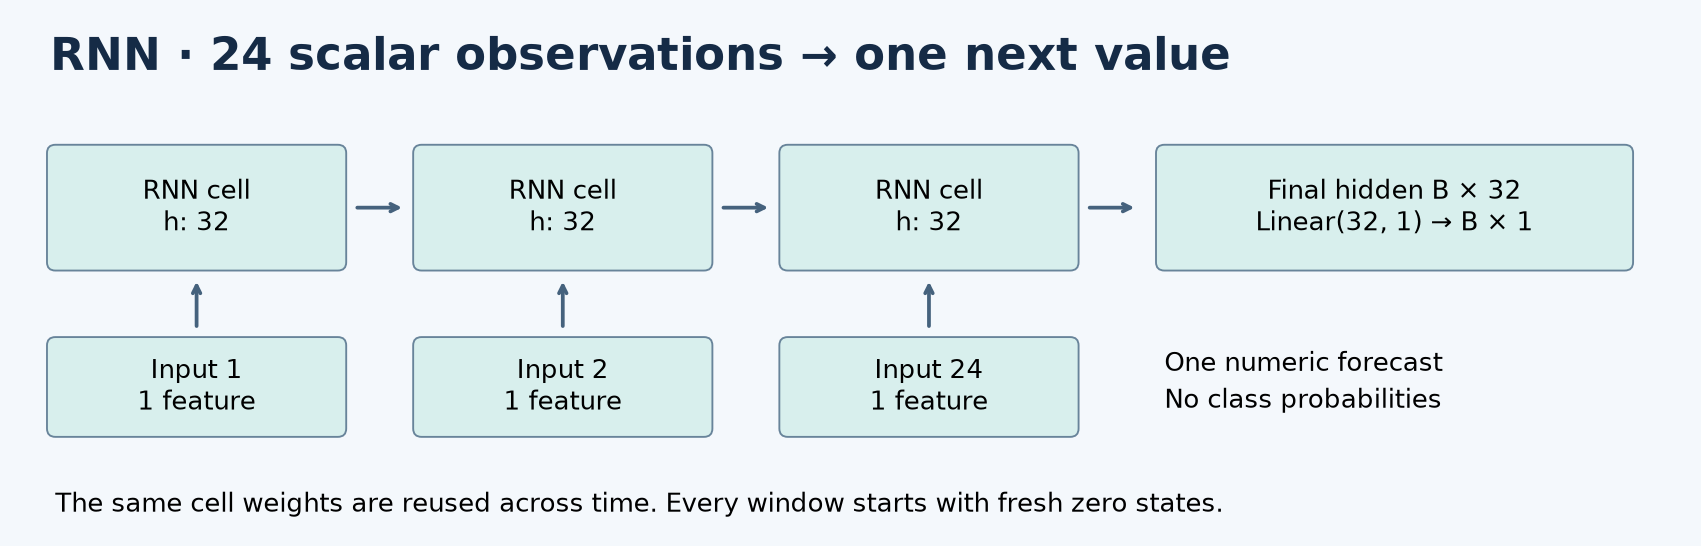

<div style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;font-size:13px;color:#64748b;text-align:center;margin:8px 0 22px">RNN architecture: 24 inputs, 32 hidden components, one regression output</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Build-and-inspect-TemperatureRNNForecaster" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Build and inspect <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">TemperatureRNNForecaster</code></h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Create a class inheriting from <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.Module</code>, call <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">super().__init__()</code>, and define a <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">recurrent</code> layer using <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.RNN(input_size=1, hidden_size=32, num_layers=1, batch_first=True)</code></strong>. Define a separate <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">head</code> using <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.Linear(32, 1)</code></strong>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">In <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">forward(x)</code>, call the recurrent layer. RNN returns the sequence outputs and final hidden tensor. Select the final layer from the hidden tensor, then pass that B × 32 vector to the linear head.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Set the seed with <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">torch.manual_seed(SEED)</code>, instantiate <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_rnn_model</code>, and move it to <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">DEVICE</code>. Print the module, count trainable parameters using <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sum(parameter.numel() for parameter in model.parameters())</code>, and demonstrate <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_X_train[:4] → (4, 1)</code>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Expected parameter count: <strong style="color:#203b58;font-weight:650;">1153</strong>. This includes recurrent input weights, recurrent hidden weights, both bias vectors and the linear head. Check shapes before beginning training.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;"><a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html" style="color:#147f86;text-underline-offset:3px;">PyTorch RNN API</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html" style="color:#147f86;text-underline-offset:3px;">Linear layer</a></p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Train-RNN-independently-and-select-a-validation-checkpoint" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Train RNN independently and select a validation checkpoint</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.MSELoss()</code></strong>, <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">torch.optim.Adam(temp_rnn_model.parameters(), lr=0.001)</code></strong>, at most <strong style="color:#203b58;font-weight:650;">100 epochs</strong>, and early-stopping patience <strong style="color:#203b58;font-weight:650;">15</strong>. Keep this model’s optimizer, history and best weights separate from the other model.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">For every epoch, switch to <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">model.train()</code>. Iterate over <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_train_loader</code>, move inputs and targets to <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">DEVICE</code>, call <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">optimizer.zero_grad()</code>, calculate predictions and MSE, call <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">loss.backward()</code>, clip using <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.utils.clip_grad_norm_(model.parameters(), 1.0)</code></strong>, then call <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">optimizer.step()</code>. Average training losses weighted by batch size.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Next, use <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">model.eval()</code> and <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">with torch.no_grad():</code></strong> for <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_val_loader</code>. Compute validation MSE without updating weights. Append training and validation losses to a history. If validation MSE improves by more than <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">1e-5</code>, save <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">copy.deepcopy(model.state_dict())</code></strong>, remember the epoch and reset the stale counter. Otherwise increment it. Stop when the counter reaches patience.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Restore the best weights with <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">model.load_state_dict(best_weights)</code></strong>. The criterion is the lowest validation MSE, not the lowest training MSE or the latest epoch. Test values must not select the checkpoint. Store this model’s results in <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_rnn_history</code>, <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_rnn_best_epoch</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_rnn_seconds</code>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">MSE compares tensors of shape <strong style="color:#203b58;font-weight:650;">B × 1</strong>. Accidentally comparing B × 1 with B can broadcast to B × B and train the wrong problem; keep the target dimension.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Evaluate-RNN,-reverse-scaling-and-draw-the-results" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Evaluate RNN, reverse scaling and draw the results</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">model.eval()</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">torch.no_grad()</code> to predict <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_X_test</code> in its existing order. Keep predictions in <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_rnn_prediction_scaled</code>, then convert to original units using <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_std</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_mean</code>; call the result <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_rnn_prediction</code>. Convert <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_y_test</code> the same way to <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_actual</code>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Calculate <strong style="color:#203b58;font-weight:650;">MAE</strong> as <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">np.mean(np.abs(prediction - actual))</code> and <strong style="color:#203b58;font-weight:650;">RMSE</strong> as <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">np.sqrt(np.mean((prediction - actual) ** 2))</code>. Save these in a dictionary <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_rnn_metrics</code>, together with model name, selected epoch and measured training time. Lower errors are better. We omit MAPE because the temperature data include zero values.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Draw two figures: the training/validation MSE histories, then actual versus predicted values on test target dates. Align dates with <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_dates.iloc[temp_target_indices[temp_test_mask]]</code>. Add axis labels, units and a legend. Display a small date/actual/prediction/error table.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Expected result: <strong style="color:#203b58;font-weight:650;">one prediction for every test target</strong>, never one class per sequence. Restore the selected validation checkpoint before evaluating.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Daily-minimum-temperature-%C2%B7-LSTM-architecture" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 11</span>Daily minimum temperature · LSTM architecture</h2><p style="font-size:18px;line-height:1.8;padding:18px 20px;background:#f1f6fa;border:1px solid #e4ecf3;border-radius:8px;margin:20px 0;overflow-x:auto;text-align:center;">$$i_t=\sigma(W_i x_t+U_i h_{t-1}+b_i),\quad f_t=\sigma(W_f x_t+U_f h_{t-1}+b_f)$$
$$g_t=\tanh(W_g x_t+U_g h_{t-1}+b_g),\quad o_t=\sigma(W_o x_t+U_o h_{t-1}+b_o)$$
$$c_t=f_t\odot c_{t-1}+i_t\odot g_t,\quad h_t=o_t\odot\tanh(c_t),\quad \hat z=w^Th_L+b.$$</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The LSTM carries hidden h and cell memory c, each with 32 components. Forget, input and output gates control retained, written and exposed information. Sigmoid gates range from zero to one; the element-wise product is written with the symbol ⊙.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use exactly <strong style="color:#203b58;font-weight:650;">one recurrent layer, one input feature and 32 hidden components</strong>. The fully connected output head is <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.Linear(32, 1)</code>. It is a regression head with <strong style="color:#203b58;font-weight:650;">one output neuron</strong> and no softmax or sigmoid. Select only the final hidden state; no hidden-state averaging or concatenation is needed.</p>
<table>
<thead>
<tr>
<th>Stage</th>
<th>Shape</th>
<th>Meaning</th>
</tr>
</thead>
<tbody>
<tr>
<td>Input</td>
<td>B × 24 × 1</td>
<td>Ordered scalar observations</td>
</tr>
<tr>
<td>All recurrent outputs</td>
<td>B × 24 × 32</td>
<td>One hidden vector per step</td>
</tr>
<tr>
<td>Final hidden returned by layer</td>
<td>1 × B × 32</td>
<td>One layer, B windows</td>
</tr>
<tr>
<td>Final features</td>
<td>B × 32</td>
<td>Select the last layer</td>
</tr>
<tr>
<td>Linear forecast</td>
<td>B × 1</td>
<td>Next scaled value</td>
</tr>
</tbody>
</table>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Initial states are zero for every window; they are not carried between unrelated minibatches.</p>
</div>

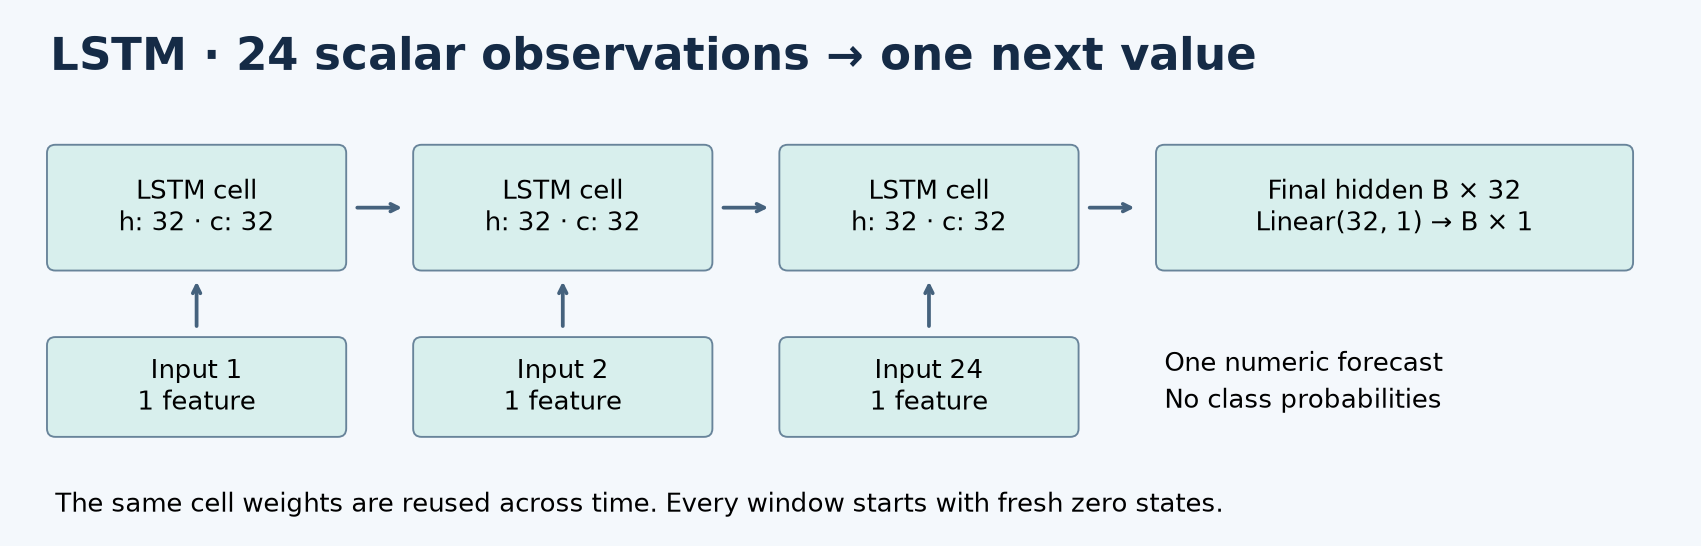

<div style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;font-size:13px;color:#64748b;text-align:center;margin:8px 0 22px">LSTM architecture: 24 inputs, 32 hidden components, one regression output</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Build-and-inspect-TemperatureLSTMForecaster" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Build and inspect <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">TemperatureLSTMForecaster</code></h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Create a class inheriting from <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.Module</code>, call <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">super().__init__()</code>, and define a <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">recurrent</code> layer using <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.LSTM(input_size=1, hidden_size=32, num_layers=1, batch_first=True)</code></strong>. Define a separate <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">head</code> using <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.Linear(32, 1)</code></strong>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">In <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">forward(x)</code>, call the recurrent layer. LSTM returns sequence outputs and a tuple of final hidden and final cell tensors; unpack that tuple and use hidden, not cell. Select the final layer from the hidden tensor, then pass that B × 32 vector to the linear head.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Set the seed with <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">torch.manual_seed(SEED)</code>, instantiate <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_lstm_model</code>, and move it to <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">DEVICE</code>. Print the module, count trainable parameters using <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">sum(parameter.numel() for parameter in model.parameters())</code>, and demonstrate <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_X_train[:4] → (4, 1)</code>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Expected parameter count: <strong style="color:#203b58;font-weight:650;">4513</strong>. This includes recurrent input weights, recurrent hidden weights, both bias vectors and the linear head. Check shapes before beginning training.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;"><a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html" style="color:#147f86;text-underline-offset:3px;">PyTorch LSTM API</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html" style="color:#147f86;text-underline-offset:3px;">Linear layer</a></p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Train-LSTM-independently-and-select-a-validation-checkpoint" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Train LSTM independently and select a validation checkpoint</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.MSELoss()</code></strong>, <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">torch.optim.Adam(temp_lstm_model.parameters(), lr=0.001)</code></strong>, at most <strong style="color:#203b58;font-weight:650;">100 epochs</strong>, and early-stopping patience <strong style="color:#203b58;font-weight:650;">15</strong>. Keep this model’s optimizer, history and best weights separate from the other model.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">For every epoch, switch to <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">model.train()</code>. Iterate over <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_train_loader</code>, move inputs and targets to <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">DEVICE</code>, call <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">optimizer.zero_grad()</code>, calculate predictions and MSE, call <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">loss.backward()</code>, clip using <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">nn.utils.clip_grad_norm_(model.parameters(), 1.0)</code></strong>, then call <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">optimizer.step()</code>. Average training losses weighted by batch size.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Next, use <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">model.eval()</code> and <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">with torch.no_grad():</code></strong> for <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_val_loader</code>. Compute validation MSE without updating weights. Append training and validation losses to a history. If validation MSE improves by more than <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">1e-5</code>, save <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">copy.deepcopy(model.state_dict())</code></strong>, remember the epoch and reset the stale counter. Otherwise increment it. Stop when the counter reaches patience.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Restore the best weights with <strong style="color:#203b58;font-weight:650;"><code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">model.load_state_dict(best_weights)</code></strong>. The criterion is the lowest validation MSE, not the lowest training MSE or the latest epoch. Test values must not select the checkpoint. Store this model’s results in <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_lstm_history</code>, <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_lstm_best_epoch</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_lstm_seconds</code>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">MSE compares tensors of shape <strong style="color:#203b58;font-weight:650;">B × 1</strong>. Accidentally comparing B × 1 with B can broadcast to B × B and train the wrong problem; keep the target dimension.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="Evaluate-LSTM,-reverse-scaling-and-draw-the-results" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">Evaluate LSTM, reverse scaling and draw the results</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">model.eval()</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">torch.no_grad()</code> to predict <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_X_test</code> in its existing order. Keep predictions in <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_lstm_prediction_scaled</code>, then convert to original units using <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_std</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_mean</code>; call the result <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_lstm_prediction</code>. Convert <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_y_test</code> the same way to <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_actual</code>.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Calculate <strong style="color:#203b58;font-weight:650;">MAE</strong> as <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">np.mean(np.abs(prediction - actual))</code> and <strong style="color:#203b58;font-weight:650;">RMSE</strong> as <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">np.sqrt(np.mean((prediction - actual) ** 2))</code>. Save these in a dictionary <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_lstm_metrics</code>, together with model name, selected epoch and measured training time. Lower errors are better. We omit MAPE because the temperature data include zero values.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Draw two figures: the training/validation MSE histories, then actual versus predicted values on test target dates. Align dates with <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_dates.iloc[temp_target_indices[temp_test_mask]]</code>. Add axis labels, units and a legend. Display a small date/actual/prediction/error table.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Expected result: <strong style="color:#203b58;font-weight:650;">one prediction for every test target</strong>, never one class per sequence. Restore the selected validation checkpoint before evaluating.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Daily-minimum-temperature-%C2%B7-compare-RNN,-LSTM-and-simple-baselines" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 12</span>Daily minimum temperature · compare RNN, LSTM and simple baselines</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Construct a table from <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_rnn_metrics</code> and <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_lstm_metrics</code>. Compare their test errors against <strong style="color:#203b58;font-weight:650;">persistence</strong>: predict the most recent observed value, obtained from <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_X_test[:, -1, 0]</code> and reversed through the scaler.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">A longer history or a gated network does not guarantee a smaller test error. Compare errors, not network complexity. Sunspots are not assumed to have a yearly seasonal cycle.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use the same test target dates for every predictor. Plot MAE and RMSE with separate axes, labels and a legend outside the bars. Record the measured ranking without changing settings based on the test results.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Daily-minimum-temperature-%C2%B7-optional-recursive-forecast" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 13</span>Daily minimum temperature · optional recursive forecast</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Start from the last <strong style="color:#203b58;font-weight:650;">24 observed scaled values</strong> of the complete series. For each of <strong style="color:#203b58;font-weight:650;">7 future steps</strong>, create a float32 tensor with shape <strong style="color:#203b58;font-weight:650;">1 × 24 × 1</strong>, predict with the selected LSTM under <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">torch.no_grad()</code>, append that scalar to the rolling history, and repeat. Later inputs contain predictions, so errors can accumulate.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Reverse scaling for the forecast and use future dates with frequency <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">D</code>. Plot recent observed values separately from forecasts and mark the dataset’s final date. These predictions are beyond the historical file’s endpoint; there are no observed future targets in this archive. Do not report test MAE for this unobserved horizon.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">temp_lstm_model</code> as selected by validation. It is not refitted on validation or test targets. This optional extension demonstrates feedback, not a guaranteed future trajectory.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Reasoning-checks" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 14</span>Reasoning checks</h2><ol>
<li>Which date determines a window’s partition: its first input or its target?</li>
<li>Why are scaler statistics fitted using only the training period?</li>
<li>Why can training windows be shuffled without shuffling the values inside each window?</li>
<li>What are the differences between <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">output</code>, final hidden and final cell in an LSTM?</li>
<li>Why does the head have one output neuron without softmax?</li>
<li>How does rolling one-step testing differ from recursive multi-step forecasting?</li>
<li>Does a lower training loss prove a better future forecast?</li>
</ol>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Compare architecture, history length, data size and baseline error before drawing conclusions. The two datasets have different physical units, so their MAEs cannot be compared as if they were on the same scale.</p>
</div>